# Dispatch & Supply Diagnostics — root cause and sizing
**Source:** Cainiao LaDe-D (Hugging Face `Cainiao-AI/LaDe-D`, CC BY-NC 4.0),
5 Chinese cities, sample **2022-06-01 to 2022-06-14, 304,286 completed
delivery tasks**. LaDe records only completed deliveries — total demand
including lost orders is NOT observed. Lost orders here are *modelled*:
shortfall in accepts vs a zone's own prior-days median, counted only in
hours with <=1 courier on shift (eyeballs). See README for definitions.
**Question:** why are some zones slow, where are orders lost, and how many
courier-hours would it cost to fix it?

In [1]:
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
pd.set_option('display.max_columns', 20)
PROJECT_ROOT = Path.cwd().parent if (Path.cwd().parent / 'data').is_dir() else Path.cwd()
ev = pd.read_csv(PROJECT_ROOT / 'data/raw/lade_delivery_events.csv', parse_dates=['date','accept_dt','delivery_dt'])
h = pd.read_csv(PROJECT_ROOT / 'data/raw/hourly_supply_demand.csv', parse_dates=['date'])
c = pd.read_csv(PROJECT_ROOT / 'data/processed/dispatch_funnel_clean.csv', parse_dates=['date','accept_hour'])
dq = pd.read_csv(PROJECT_ROOT / 'data/processed/dq_alerts.csv')
print('events', len(ev), '| zone-hours (clean)', len(c), '| hourly grid', len(h))
print(dq.to_string(index=False))

events 304286 | zone-hours (clean) 17784 | hourly grid 54432
                    check_name  failed_rows  total_rows  fail_pct verdict
            duplicate_order_id            0      304286  0.000000    PASS
negative_accept_to_deliver_min            0      304286  0.000000    PASS
             duration_over_12h         3684      304286  1.210703    WARN
               null_accept_gps          640      304286  0.210328    PASS
             null_delivery_gps            0      304286  0.000000    PASS
          null_zone_or_courier            0      304286  0.000000    PASS
     delivery_before_accept_dt            0      304286  0.000000    PASS
              date_ds_mismatch            0      304286  0.000000    PASS


## 1. Funnel — how slow is accept-to-deliver?
Duration is accept-to-deliver in minutes (courier accepts a task, then
delivers it). Durations over 12h (3,684 orders, 1.2%) are flagged in DQ
and excluded from speed percentiles, not deleted.

In [2]:
print(ev['accept_to_deliver_min'].describe().round(1))
print('\nBy city (event level):')
print(ev.groupby('city')['accept_to_deliver_min'].agg(['count','median',lambda s: s.quantile(0.9)]).round(1))
print('\nBy hour band (accept hour):')
ev['hour'] = ev['accept_dt'].dt.hour
ev['band'] = pd.cut(ev['hour'], [-1,5,11,16,22,23], labels=['night 0-5','morning 6-11','afternoon 12-16','evening 17-22','late 23'])
print(ev.groupby('band', observed=True)['accept_to_deliver_min'].agg(['count','median',lambda s: s.quantile(0.9)]).round(1))

count    304286.0
mean        159.2
std         159.2
min           0.0
25%          62.0
50%         115.0
75%         201.0
max        1439.0
Name: accept_to_deliver_min, dtype: float64

By city (event level):
            count  median  <lambda_0>
city                                 
Chongqing   70267   146.0       413.0
Hangzhou   137459   114.0       283.0
Jilin        3159   159.0       369.0
Shanghai    74980    81.0       242.0
Yantai      18421   215.0       516.0

By hour band (accept hour):
                  count  median  <lambda_0>
band                                       
night 0-5           191   149.0       357.0
morning 6-11     146365   151.0       415.0
afternoon 12-16  122430    97.0       269.0
evening 17-22     35131    60.0       160.0
late 23             169     5.0        20.0


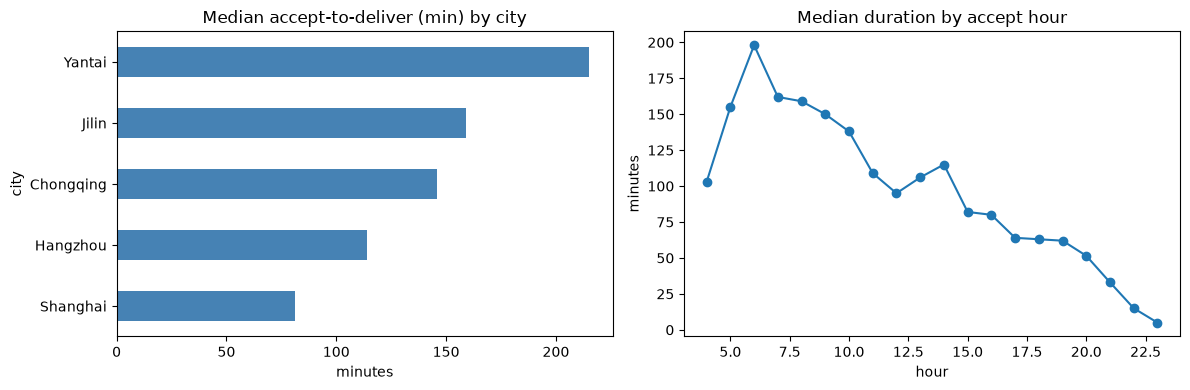

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ev.groupby('city')['accept_to_deliver_min'].median().sort_values().plot.barh(ax=ax[0], color='steelblue')
ax[0].set_title('Median accept-to-deliver (min) by city'); ax[0].set_xlabel('minutes')
ev.groupby('hour')['accept_to_deliver_min'].median().plot(ax=ax[1], marker='o')
ax[1].set_title('Median duration by accept hour'); ax[1].set_xlabel('hour'); ax[1].set_ylabel('minutes')
plt.tight_layout(); plt.show()

## 2. Root cause 1 — load: requests per active courier
At zone-hour level, load = requests / active couriers. Median duration
rises monotonically with load. This is the strongest operational driver
found (see OLS below).

In [4]:
c['load'] = c['requests'] / c['active_couriers']
c['load_bin'] = pd.cut(c['load'], [0,1,2,3,5,10,100], labels=['<=1','1-2','2-3','3-5','5-10','>10'])
print(c.groupby('load_bin', observed=True).agg(zone_hours=('median_min','count'), orders=('requests','sum'), median_min=('median_min','median'), p90_min=('p90_min','median')).round(1))
print('\ncorr(load, zone-hour median):', round(c[['load','median_min']].corr().iloc[0,1], 3))
print('corr(requests, zone-hour median):', round(c[['requests','median_min']].corr().iloc[0,1], 3))
print('corr(eyeballs, zone-hour median):', round(c[['eyeballs','median_min']].corr().iloc[0,1], 3))

          zone_hours  orders  median_min  p90_min
load_bin                                         
<=1             4089    5907        35.0     42.0
1-2             3055   14807        61.0    119.2
2-3             2254   20043        66.0    133.0
3-5             2921   42616        78.5    155.8
5-10            3384   90108       108.0    202.2
>10             2081  127121       146.0    272.0

corr(load, zone-hour median): 0.222
corr(requests, zone-hour median): 0.142
corr(eyeballs, zone-hour median): -0.032


In [5]:
import statsmodels.api as sm
d = c.dropna(subset=['load','median_min']).copy()
X = pd.get_dummies(d[['load','city']], columns=['city'], drop_first=True, dtype=float)
X = sm.add_constant(X)
m = sm.OLS(d['median_min'], X).fit()
print(m.summary().tables[1])
print('R2 =', round(m.rsquared, 3))
print('\nReading: each extra order per courier in a zone-hour adds ~5 min to the')
print('hourly median, holding city constant. City effects are large: Hangzhou')
print('and Shanghai are structurally ~50-70 min faster than Chongqing at the')
print('same load. R2 is only 0.14 — load matters, but it is not the whole story.')

                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const           128.9437      1.757     73.387      0.000     125.500     132.388
load              5.1589      0.169     30.449      0.000       4.827       5.491
city_Hangzhou   -70.8242      2.028    -34.923      0.000     -74.799     -66.849
city_Jilin       -0.1028      5.774     -0.018      0.986     -11.420      11.214
city_Shanghai   -53.9040      1.984    -27.169      0.000     -57.793     -50.015
city_Yantai      23.0923      3.405      6.781      0.000      16.417      29.767
R2 = 0.14

Reading: each extra order per courier in a zone-hour adds ~5 min to the
hourly median, holding city constant. City effects are large: Hangzhou
and Shanghai are structurally ~50-70 min faster than Chongqing at the
same load. R2 is only 0.14 — load matters, but it is not the whole story.


## 3. Root cause 2 — zero / thin supply and lost orders
Zeroes are read from the full zone-hour grid (`hourly_supply_demand.csv`),
not from the funnel table (which only has hours with at least one order).
Lost orders are modelled, only in hours with <=1 courier on shift.

In [6]:
print('Zero-supply zone-hours:', int(h['zeroes'].sum()), '/', len(h), f"({h['zeroes'].mean()*100:.1f}%)")
print('Peak hours 07-22 zeroes:', f"{h[(h['hour']>=7)&(h['hour']<=22)]['zeroes'].mean()*100:.1f}%")
print('\nZeroes by hour band:')
h['band'] = pd.cut(h['hour'], [-1,5,11,16,22,23], labels=['night 0-5','morning 6-11','afternoon 12-16','evening 17-22','late 23'])
print((h.groupby('band', observed=True)['zeroes'].mean()*100).round(1))
print('\nModelled lost orders (14 days):', round(h['lost_orders_est'].sum(), 1), '=', round(h['lost_orders_est'].sum()/14, 1), 'per day')
print(h.groupby('city')['lost_orders_est'].sum().sort_values(ascending=False).round(1))
print('\nWorst zones by modelled lost orders:')
print(h.groupby(['city','zone_id'])['lost_orders_est'].sum().sort_values(ascending=False).head(10).round(1))

Zero-supply zone-hours: 31645 / 54432 (58.1%)
Peak hours 07-22 zeroes: 37.7%

Zeroes by hour band:
band
night 0-5          99.8
morning 6-11       40.2
afternoon 12-16    18.3
evening 17-22      61.2
late 23            96.4
Name: zeroes, dtype: float64

Modelled lost orders (14 days): 20698.5 = 1478.5 per day
city
Hangzhou     8894.0
Chongqing    5069.0
Shanghai     3284.0
Yantai       2926.0
Jilin         525.5
Name: lost_orders_est, dtype: float64

Worst zones by modelled lost orders:
city       zone_id
Hangzhou   60         901.5
           96         496.5
Yantai     128        446.5
Chongqing  103        441.0
Hangzhou   94         365.0
Yantai     151        357.0
Hangzhou   119        330.5
           62         317.0
Yantai     115        314.0
Chongqing  158        298.0
Name: lost_orders_est, dtype: float64


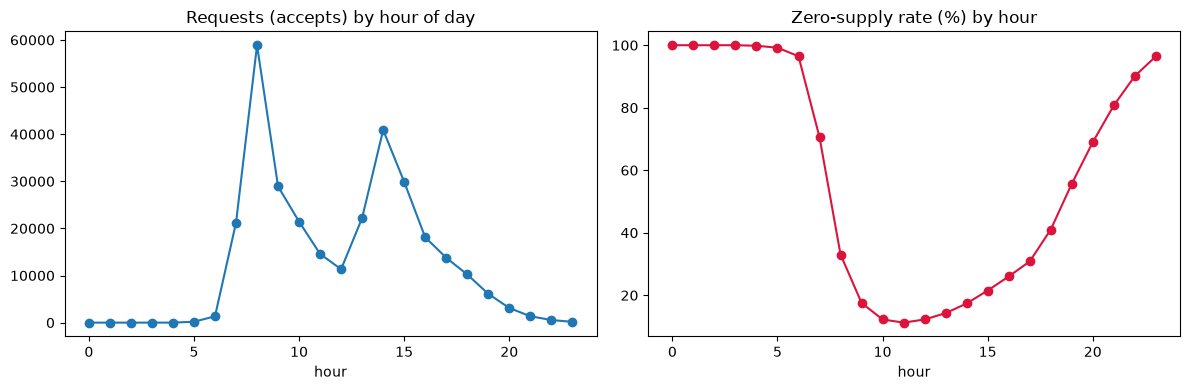

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
(h.groupby('hour')['requests'].sum()).plot(ax=ax[0], marker='o')
ax[0].set_title('Requests (accepts) by hour of day'); ax[0].set_xlabel('hour')
(h.groupby('hour')['zeroes'].mean()*100).plot(ax=ax[1], marker='o', color='crimson')
ax[1].set_title('Zero-supply rate (%) by hour'); ax[1].set_xlabel('hour')
plt.tight_layout(); plt.show()

## 4. Sizing — speed vs cost
Two interventions, costed at an **assumed** courier cost of CNY 30/hour
(LaDe has no pay data; sensitivity at CNY 20 / 40 is shown). Costs are
courier-hours, not a promise that every modelled lost order is recovered.
**A — cover zero-supply peak hours:** 1 courier in every zero-supply
zone-hour, 07:00-22:00. **B — cut load in busy hours:** add couriers until
load <= 3 (or <= 5) in every zone-hour above that load.

In [8]:
peak = h[(h['hour']>=7)&(h['hour']<=22)]
zero_hours_day = peak['zeroes'].sum()/14
print(f"A: zero peak zone-hours per day: {zero_hours_day:.0f} courier-hours/day")
for rate in [20, 30, 40]:
    print(f"   cost/day at CNY {rate}/h: CNY {zero_hours_day*rate:,.0f}")
print(f"   modelled lost orders in peak hours: {peak['lost_orders_est'].sum()/14:.0f}/day")
print(f"   cost per modelled lost order if all were recovered: CNY {zero_hours_day*30/(peak['lost_orders_est'].sum()/14):.0f} (upper bound, recovery is not 1:1)")
print()
for target in [5, 3, 2]:
    extra = (c['requests']/target - c['active_couriers']).clip(lower=0)
    print(f"B: target load <={target}: +{extra.sum()/14:.0f} courier-hours/day, "
          f"CNY {extra.sum()/14*30:,.0f}/day at CNY 30/h "
          f"(CNY {extra.sum()/14*20:,.0f} at 20, CNY {extra.sum()/14*40:,.0f} at 40), "
          f"{int((extra>0).sum())} zone-hours affected")
print()
print('Expected speed gain (binned association, not causal): zone-hours at load')
print('>5 have median 108-146 min; at load 3-5 the median is 78.5 min, at')
print('load 2-3 it is 66 min. So intervention B moves busy hours toward')
print('~66-79 min median, from ~108-146 min.')

A: zero peak zone-hours per day: 977 courier-hours/day
   cost/day at CNY 20/h: CNY 19,549
   cost/day at CNY 30/h: CNY 29,323
   cost/day at CNY 40/h: CNY 39,097
   modelled lost orders in peak hours: 1417/day
   cost per modelled lost order if all were recovered: CNY 21 (upper bound, recovery is not 1:1)

B: target load <=5: +1571 courier-hours/day, CNY 47,142/day at CNY 30/h (CNY 31,428 at 20, CNY 62,857 at 40), 5465 zone-hours affected
B: target load <=3: +3904 courier-hours/day, CNY 117,111/day at CNY 30/h (CNY 78,074 at 20, CNY 156,149 at 40), 8386 zone-hours affected
B: target load <=2: +7171 courier-hours/day, CNY 215,121/day at CNY 30/h (CNY 143,414 at 20, CNY 286,829 at 40), 10640 zone-hours affected

Expected speed gain (binned association, not causal): zone-hours at load
>5 have median 108-146 min; at load 3-5 the median is 78.5 min, at
load 2-3 it is 66 min. So intervention B moves busy hours toward
~66-79 min median, from ~108-146 min.


## 5. Recommendation
1. **Start with A, in Hangzhou and Chongqing.** Hangzhou loses the most
modelled orders (635/day) and Chongqing is next (362/day); the worst
single zones are Hangzhou 60 (902 modelled lost in 14 days) and
Hangzhou 96 (497). Staffing 1 courier per zero peak zone-hour costs
~CNY 29k/day at the assumed rate.
2. **Then B in the morning peak (06:00-11:00).** Morning is the slowest
band (median 151 min) and the biggest volume (146,365 orders, 08:00
alone is 58,888). Cutting load to <=3 costs ~CNY 117k/day — do it only
in the worst morning zones first, not everywhere.
3. **Do not build a policy on the 23:00 band.** Only 169 orders, median
5 min — a small-n artefact, not a real fast hour.
## Limitations — do not overclaim
- LaDe records completed deliveries only; lost orders are modelled, not observed.
- Eyeballs are a derived on-shift proxy (first-to-last accept in a zone-day);
LaDe has no online/session feed.
- Duration is accept-to-deliver, not pure travel time; it includes waiting
and batching at the station.
- The load-duration link is an association (R2 0.14); the sizing is a
scenario, not a causal estimate. Courier cost CNY 30/h is an assumption.
- Sample is 14 days in June 2022, 5 Chinese cities; do not generalise to
other seasons, cities, or platforms (e.g. Mrsool / Saudi).